In [1]:
!pip install --no-index --find-links /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages segmentation-models-pytorch albumentations omegaconf torchmetrics

Looking in links: /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages
Processing /kaggle/input/datasets/hinlphmhng/uav-seg-offline-assets/offline_assets/packages/segmentation_models_pytorch-0.5.0-py3-none-any.whl


In [2]:
# ============================================================
# CONFIG — the only cell that differs between runs
# ============================================================
import time
SESSION_START = time.time()

RUN_NAME     = 'R13_unetpp_ce_s42'
MODEL_NAME   = 'unetpp'
ENCODER      = 'resnet50'
LOSS         = 'ce'        # ce | ced | cef | cefd | adaptive | lovasz | focal_tversky | unified_focal | dwa
SEED         = 42
USE_AMP      = True
AMP_DTYPE    = 'float16'   # 'float16' (with GradScaler) or 'bfloat16' (fp32 range, no overflow)
PATIENCE     = 10

LR           = 1e-4
WEIGHT_DECAY = 1e-4
EPOCHS       = 50
BATCH_SIZE   = 4
IMG_SIZE     = (768, 1280)
NUM_WORKERS  = 32
MAX_HOURS    = 11.0           # stop cleanly (last.pth saved) before Kaggle's 12 h limit

# Resume: add the previous session's output as an input dataset and put its folder here.
# Leave '' for a fresh start.
RESUME_DIR   = '/kaggle/input/datasets/wennni/r13-checkpoint'

ENCODER_WEIGHT_DIR = '/kaggle/input/datasets/itmeagain77/resnet50-pytorch-weights'
print(f'[CONFIG] {RUN_NAME} | {MODEL_NAME}/{ENCODER} | loss={LOSS} | seed={SEED} | amp={USE_AMP} | wd={WEIGHT_DECAY}')

[CONFIG] R13_unetpp_ce_s42 | unetpp/resnet50 | loss=ce | seed=42 | amp=True | wd=0.0001


In [3]:
import os
from pathlib import Path

SUNNY_DIRS = [
    Path('/kaggle/input/datasets/leehien12/uav-forest-sunny-part1'),
    Path('/kaggle/input/datasets/khesng/uav-forest-sunny-next'),
    Path('/kaggle/input/datasets/leehien12/uav-forest-sunny'),
]
OVERCAST_DIRS = [
    Path('/kaggle/input/datasets/hinlphmhng/uav-forest-overcast-1'),
    Path('/kaggle/input/datasets/hinlphmhng/uav-forest-overcast-2'),
]
SPLIT_CONFIG = {
    'train': ['seq1', 'seq3', 'seq4', 'seq5', 'seq8', 'seq9',
              'seq10', 'seq12', 'seq14', 'seq15', 'seq16', 'seq17'],
    'val':   ['seq2', 'seq13', 'seq18'],
    'test':  ['seq6', 'seq7', 'seq11'],
}

def collect_pairs_from_dirs(base_dirs, split_config):
    data = {'train': [], 'val': [], 'test': []}
    found = {}
    for base_path in base_dirs:
        if not Path(base_path).exists():
            print(f'  [WARN] missing: {base_path}')
            continue
        for color_dir in Path(base_path).rglob('color'):
            if not color_dir.is_dir():
                continue
            seq_dir, seq_name = color_dir.parent, color_dir.parent.name
            mask_dir = seq_dir / 'labels'
            if not mask_dir.exists():
                mask_dir = seq_dir / 'label'
            if not mask_dir.exists():
                continue
            target = next((k for k, v in split_config.items() if seq_name in v), None)
            if target is None:
                continue
            n = 0
            for img_p in sorted(list(color_dir.glob('*.png')) + list(color_dir.glob('*.jpg'))):
                mask_p = (mask_dir / img_p.name).with_suffix('.png')
                if not mask_p.exists():
                    mask_p = (mask_dir / img_p.name).with_suffix('.jpg')
                if mask_p.exists():
                    data[target].append((str(img_p), str(mask_p)))
                    n += 1
            found[seq_name] = (target, n)
    return data, found

data, found_seqs = collect_pairs_from_dirs(SUNNY_DIRS + OVERCAST_DIRS, SPLIT_CONFIG)
train_files, val_files, test_files = data['train'], data['val'], data['test']
missing = set(sum(SPLIT_CONFIG.values(), [])) - set(found_seqs)
assert not missing, f'Missing sequences: {sorted(missing)}'
print(f'TRAIN {len(train_files):,} | VAL {len(val_files):,} | TEST {len(test_files):,}')
assert (len(train_files), len(val_files), len(test_files)) == (17454, 4297, 4491), 'Unexpected split sizes'


TRAIN 17,454 | VAL 4,297 | TEST 4,491


In [4]:
import numpy as np
from PIL import Image

LABEL_COLORS = [
    (0, 255, 255), (0, 127, 0), (19, 132, 69), (0, 53, 65), (130, 76, 0),
    (152, 251, 152), (151, 126, 171), (250, 150, 0), (115, 176, 195),
    (123, 123, 123), (0, 0, 0),
]
CLASS_NAMES = ['Sky', 'Deciduous_trees', 'Coniferous_trees', 'Fallen_trees',
               'Dirt_ground', 'Ground_vegetation', 'Rocks', 'Building',
               'Fence', 'Car', 'Empty']
NUM_CLASSES = len(CLASS_NAMES)   # 11, Empty = index 10
EMPTY_CLASS = NUM_CLASSES - 1
PALETTE = np.array(LABEL_COLORS, dtype=np.uint8)

RGB_TO_CLASS_LUT = np.full((256, 256, 256), EMPTY_CLASS, dtype=np.uint8)
for cid, color in enumerate(LABEL_COLORS):
    RGB_TO_CLASS_LUT[color] = cid

def fast_rgb_to_mask(rgb_arr):
    return RGB_TO_CLASS_LUT[rgb_arr[..., 0], rgb_arr[..., 1], rgb_arr[..., 2]]


In [5]:
import random
import torch

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('[INFO] Device:', torch.cuda.get_device_name() if DEVICE == 'cuda' else 'cpu')

OUTPUT_DIR = Path('/kaggle/working/outputs') if os.path.exists('/kaggle') else Path('outputs')
CKPT_DIR = OUTPUT_DIR / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)


[INFO] Device: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [6]:
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

class ForestDataset(Dataset):
    def __init__(self, file_list, transform=None):
        self.file_list = file_list
        self.transform = transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        img_path, mask_path = self.file_list[idx]
        img = np.array(Image.open(img_path).convert('RGB'))
        mask = fast_rgb_to_mask(np.array(Image.open(mask_path).convert('RGB')))
        if self.transform:
            aug = self.transform(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']
        return img, mask.long()

H, W = IMG_SIZE
train_tf = A.Compose([
    A.Resize(height=H, width=W),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), rotate=(-15, 15),
             translate_percent={'x': (-0.0625, 0.0625), 'y': (-0.0625, 0.0625)},
             p=0.3, border_mode=0, fill=0, fill_mask=EMPTY_CLASS),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
val_tf = A.Compose([
    A.Resize(height=H, width=W),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

def worker_init_fn(worker_id):
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)

train_ds = ForestDataset(train_files, train_tf)
val_ds = ForestDataset(val_files, val_tf)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                          persistent_workers=True, prefetch_factor=2,
                          worker_init_fn=worker_init_fn,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=16, pin_memory=True,
                        persistent_workers=True, prefetch_factor=2)
print(f'[OK] Train {len(train_loader)} batches | Val {len(val_loader)} batches')


[OK] Train 4363 batches | Val 1075 batches


/usr/local/lib/python3.12/dist-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno -3] Temporary failure in name resolution>
  data = fetch_version_info()


In [7]:
import shutil, glob
import torch.nn as nn
import segmentation_models_pytorch as smp

CACHE_DIR = '/root/.cache/torch/hub/checkpoints/'
os.makedirs(CACHE_DIR, exist_ok=True)
cache_name = {'resnet50': 'resnet50-19c8e357.pth', 'mit_b4': 'mit_b4.pth'}[ENCODER]
pth_files = glob.glob(os.path.join(ENCODER_WEIGHT_DIR, '*.pth'))
if pth_files and not os.path.exists(os.path.join(CACHE_DIR, cache_name)):
    shutil.copy(pth_files[0], os.path.join(CACHE_DIR, cache_name))
print('[OK] encoder weights:', pth_files[:1] or 'download from internet')

MODELS = {
    'unet':          smp.Unet,
    'unetpp':        smp.UnetPlusPlus,
    'deeplabv3plus': smp.DeepLabV3Plus,
    'segformer':     smp.Segformer,
    'manet':         smp.MAnet,
    'upernet':       smp.UPerNet,
}
model = MODELS[MODEL_NAME](encoder_name=ENCODER, encoder_weights='imagenet',
                           in_channels=3, classes=NUM_CLASSES).to(DEVICE)
print(f'[MODEL] {MODEL_NAME}/{ENCODER} | params {sum(p.numel() for p in model.parameters()):,}')


[OK] encoder weights: ['/kaggle/input/datasets/itmeagain77/resnet50-pytorch-weights/resnet50-19c8e357.pth']


'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/smp-hub/resnet50.imagenet/resolve/00cb74e366966d59cd9a35af57e618af9f88efe9/config.json
Retrying in 1s [Retry 1/5].
/usr/local/lib/python3.12/dist-packages/segmentation_models_pytorch/encoders/__init__.py:136: UserWarning: Error loading resnet50 `imagenet` weights from Hugging Face Hub, trying loading from original url...
  warnings.warn(message, UserWarning)


[MODEL] unetpp/resnet50 | params 48,987,195


In [8]:
from tqdm import tqdm

# ENet weights w = 1/ln(1.02 + f_c), normalised to sum to NUM_CLASSES,
# computed once on the fixed training split (17,454 frames).
class_weights = torch.tensor([0.2260, 0.2128, 0.1355, 1.4142, 0.9162, 0.1129,
                              0.9421, 1.6558, 1.8006, 1.7720, 1.8119],
                             dtype=torch.float32).to(DEVICE)


In [9]:
# ============================================================
# LOSSES — every criterion returns (loss, components) with the same keys
# ============================================================
import torch.nn.functional as F

def make_ce():
    return nn.CrossEntropyLoss(weight=class_weights, ignore_index=EMPTY_CLASS)

def make_focal():
    return smp.losses.FocalLoss(mode=smp.losses.MULTICLASS_MODE, gamma=2.0)

def make_dice():
    return smp.losses.DiceLoss(mode=smp.losses.MULTICLASS_MODE, from_logits=True,
                               classes=list(range(NUM_CLASSES - 1)))

class FixedWeightLoss(nn.Module):
    """Exp1 (ce), Exp2-CED, Exp2-CEF, Exp2-CEFD (1:1:1): static weights."""
    def __init__(self, w_ce=1.0, w_focal=0.0, w_dice=0.0):
        super().__init__()
        self.w = {'ce': w_ce, 'focal': w_focal, 'dice': w_dice}
        self.ce = make_ce()
        self.focal = make_focal() if w_focal else None
        self.dice = make_dice() if w_dice else None

    def forward(self, logits, targets):
        l = {'ce': self.ce(logits, targets)}
        l['focal'] = self.focal(logits, targets) if self.focal else torch.zeros((), device=logits.device)
        l['dice'] = self.dice(logits, targets) if self.dice else torch.zeros((), device=logits.device)
        loss = sum(self.w[k] * l[k] for k in l)
        return loss, {**{k: v.item() for k, v in l.items()}, **{f'w_{k}': self.w[k] for k in l}}

    def get_weights(self):
        return {f'w_{k}': v for k, v in self.w.items()}

class AdaptiveFocalDiceLoss(nn.Module):
    """Exp3: homoscedastic uncertainty weighting (Kendall et al., 2018).
    Logged w_* = exp(-s_k); the effective weight in the paper is 0.5*exp(-s_k)."""
    def __init__(self):
        super().__init__()
        self.focal, self.dice, self.ce = make_focal(), make_dice(), make_ce()
        self.log_sigma_focal = nn.Parameter(torch.zeros(1))
        self.log_sigma_dice = nn.Parameter(torch.zeros(1))
        self.log_sigma_ce = nn.Parameter(torch.zeros(1))

    def forward(self, logits, targets):
        l_f, l_d, l_c = self.focal(logits, targets), self.dice(logits, targets), self.ce(logits, targets)
        w_f, w_d, w_c = (torch.exp(-s) for s in (self.log_sigma_focal, self.log_sigma_dice, self.log_sigma_ce))
        loss = (0.5 * w_f * l_f + 0.5 * self.log_sigma_focal
                + 0.5 * w_d * l_d + 0.5 * self.log_sigma_dice
                + 0.5 * w_c * l_c + 0.5 * self.log_sigma_ce)
        return loss.squeeze(), {'focal': l_f.item(), 'dice': l_d.item(), 'ce': l_c.item(),
                                'w_focal': w_f.item(), 'w_dice': w_d.item(), 'w_ce': w_c.item()}

    def get_weights(self):
        return {'w_focal': torch.exp(-self.log_sigma_focal).item(),
                'w_dice': torch.exp(-self.log_sigma_dice).item(),
                'w_ce': torch.exp(-self.log_sigma_ce).item()}

class CEPlusLoss(nn.Module):
    """Baselines: weighted CE + an overlap loss (Lovasz-Softmax or Focal-Tversky), 1:1."""
    def __init__(self, second):
        super().__init__()
        self.ce = make_ce()
        if second == 'lovasz':
            # Berman et al., CVPR 2018
            self.second = smp.losses.LovaszLoss(mode=smp.losses.MULTICLASS_MODE,
                                                ignore_index=EMPTY_CLASS, from_logits=True)
        else:
            # Focal-Tversky (Abraham & Khan, 2019): FN weight 0.7, FP weight 0.3, exponent 1/gamma = 0.75.
            # smp: alpha weights FP, beta weights FN; gamma is applied to the class-averaged loss.
            self.second = smp.losses.TverskyLoss(mode=smp.losses.MULTICLASS_MODE,
                                                 classes=list(range(NUM_CLASSES - 1)),
                                                 from_logits=True, alpha=0.3, beta=0.7, gamma=0.75)

    def forward(self, logits, targets):
        l_c, l_s = self.ce(logits, targets), self.second(logits, targets)
        # the overlap term is logged in the 'dice' column of the CSV
        return l_c + l_s, {'focal': 0.0, 'dice': l_s.item(), 'ce': l_c.item(),
                           'w_focal': 0.0, 'w_dice': 1.0, 'w_ce': 1.0}

    def get_weights(self):
        return {'w_focal': 0.0, 'w_dice': 1.0, 'w_ce': 1.0}

class UnifiedFocalLoss(nn.Module):
    """Symmetric Unified Focal loss (Yeung et al., CMIG 2022), multi-class version.
    Follows the official implementation (mlyg/unified-focal-loss, sym_unified_focal_loss):
      L = lam * L_focal_tversky + (1 - lam) * L_focal,  lam=0.5, delta=0.6, gamma=0.5
      L_focal          = mean_i (1 - p_t)^gamma * (-log p_t)
      L_focal_tversky  = mean_c (1 - TI_c)^(1 - gamma),  TI_c = TP/(TP + delta*FN + (1-delta)*FP)
    Extended to multi-class by weighting all foreground classes equally; Empty pixels are ignored."""
    def __init__(self, lam=0.5, delta=0.6, gamma=0.5, eps=1e-7):
        super().__init__()
        self.lam, self.delta, self.gamma, self.eps = lam, delta, gamma, eps

    def forward(self, logits, targets):
        logits = logits.float()
        valid = targets != EMPTY_CLASS
        prob = F.softmax(logits, dim=1).clamp(self.eps, 1 - self.eps)
        tgt = targets.clone()
        tgt[~valid] = 0
        p_t = prob.gather(1, tgt.unsqueeze(1)).squeeze(1)[valid]
        l_focal = ((1 - p_t) ** self.gamma * -torch.log(p_t)).mean()

        C = NUM_CLASSES - 1
        onehot = F.one_hot(tgt, NUM_CLASSES).permute(0, 3, 1, 2).float()[:, :C]
        p = prob[:, :C] * valid.unsqueeze(1)
        onehot = onehot * valid.unsqueeze(1)
        dims = (0, 2, 3)
        tp, fn, fp = (p * onehot).sum(dims), ((1 - p) * onehot).sum(dims), (p * (1 - onehot)).sum(dims)
        ti = (tp + self.eps) / (tp + self.delta * fn + (1 - self.delta) * fp + self.eps)
        present = onehot.sum(dims) > 0
        l_ft = ((1 - ti[present]) ** (1 - self.gamma)).mean()

        loss = self.lam * l_ft + (1 - self.lam) * l_focal
        return loss, {'focal': l_focal.item(), 'dice': l_ft.item(), 'ce': 0.0,
                      'w_focal': 1 - self.lam, 'w_dice': self.lam, 'w_ce': 0.0}

    def get_weights(self):
        return {'w_focal': 1 - self.lam, 'w_dice': self.lam, 'w_ce': 0.0}

class DWALoss(nn.Module):
    """Dynamic Weight Average (Liu et al., CVPR 2019) over CE, Focal and Dice.
    lambda_k(t) = K * softmax_k(r_k / T), r_k = L_k(t-1) / L_k(t-2), T = 2; lambda = 1 for the first two epochs."""
    KEYS = ('ce', 'focal', 'dice')

    def __init__(self, T=2.0):
        super().__init__()
        self.T = T
        self.ce, self.focal, self.dice = make_ce(), make_focal(), make_dice()
        self.register_buffer('hist', torch.zeros(2, 3))      # epoch-mean losses of t-2, t-1
        self.register_buffer('n_epochs', torch.zeros((), dtype=torch.long))
        self.register_buffer('lam', torch.ones(3))

    def end_epoch(self, avg):
        cur = torch.tensor([avg[k] for k in self.KEYS], device=self.hist.device)
        self.hist[0] = self.hist[1].clone()
        self.hist[1] = cur
        self.n_epochs += 1
        if self.n_epochs >= 2:
            r = self.hist[1] / self.hist[0].clamp_min(1e-12)
            self.lam = 3 * torch.softmax(r / self.T, dim=0)

    def forward(self, logits, targets):
        l = {'ce': self.ce(logits, targets), 'focal': self.focal(logits, targets), 'dice': self.dice(logits, targets)}
        loss = sum(self.lam[i] * l[k] for i, k in enumerate(self.KEYS))
        return loss, {**{k: v.item() for k, v in l.items()},
                      **{f'w_{k}': self.lam[i].item() for i, k in enumerate(self.KEYS)}}

    def get_weights(self):
        return {f'w_{k}': self.lam[i].item() for i, k in enumerate(self.KEYS)}

def build_criterion(name):
    if name == 'ce':            return FixedWeightLoss(1.0, 0.0, 0.0)
    if name == 'ced':           return FixedWeightLoss(1.0, 0.0, 1.0)
    if name == 'cef':           return FixedWeightLoss(1.0, 1.0, 0.0)
    if name == 'cefd':          return FixedWeightLoss(1.0, 1.0, 1.0)
    if name == 'adaptive':      return AdaptiveFocalDiceLoss()
    if name == 'lovasz':        return CEPlusLoss('lovasz')
    if name == 'focal_tversky': return CEPlusLoss('focal_tversky')
    if name == 'unified_focal': return UnifiedFocalLoss()
    if name == 'dwa':           return DWALoss()
    raise ValueError(name)

criterion = build_criterion(LOSS).to(DEVICE)
optimizer = torch.optim.AdamW(list(model.parameters()) + list(criterion.parameters()),
                              lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
print(f'[LOSS] {LOSS} -> {type(criterion).__name__} | initial weights {criterion.get_weights()}')


[LOSS] ce -> FixedWeightLoss | initial weights {'w_ce': 1.0, 'w_focal': 0.0, 'w_dice': 0.0}


In [10]:
def confusion(model_, loader, desc):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    total_loss, n = 0.0, 0
    with torch.no_grad():
        for imgs, masks in tqdm(loader, desc=desc):
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                out = model_(imgs)
                loss, _ = criterion(out, masks)
            total_loss += loss.item(); n += 1
            p = out.argmax(1).cpu().numpy().ravel()
            t = masks.cpu().numpy().ravel()
            cm += np.bincount(t * NUM_CLASSES + p, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)
    return cm, total_loss / max(n, 1)

def metrics_from_cm(cm):
    """Per-class IoU/recall/precision for the 10 foreground classes; mIoU = their mean."""
    tp = np.diag(cm).astype(float)
    gt, pred = cm.sum(1).astype(float), cm.sum(0).astype(float)
    iou = np.divide(tp, gt + pred - tp, out=np.zeros_like(tp), where=(gt + pred - tp) > 0)
    rec = np.divide(tp, gt, out=np.zeros_like(tp), where=gt > 0)
    prec = np.divide(tp, pred, out=np.zeros_like(tp), where=pred > 0)
    fg = slice(0, NUM_CLASSES - 1)
    return float(iou[fg].mean()), iou[fg], rec[fg], prec[fg]


In [12]:
# ============================================================
# RESUME (only if RESUME_DIR is set)
# ============================================================
import csv, json

LOG_FILE = OUTPUT_DIR / 'training_log.csv'
start_epoch, best_val_miou, best_epoch, no_improve = 1, -1.0, 0, 0

def find_one(root, suffix):
    """First file under root whose name ends with suffix (accepts e.g. R01_..._last.pth)."""
    hits = sorted(p for p in Path(root).rglob('*') if p.is_file() and p.name.endswith(suffix))
    return hits[0] if hits else None

if RESUME_DIR:
    rd = Path(RESUME_DIR)
    assert rd.exists(), f'RESUME_DIR does not exist: {rd}. Check the path in the Input panel.'
    last = find_one(rd, 'last.pth')
    if last is None:
        found = [str(p.relative_to(rd)) for p in rd.rglob('*') if p.is_file()]
        raise FileNotFoundError(f'No *last.pth under {rd}. Files found: {found[:20]}')
    ck = torch.load(last, map_location=DEVICE, weights_only=False)
    assert ck['run_name'] == RUN_NAME, f"Checkpoint belongs to {ck['run_name']}, not {RUN_NAME}"
    model.load_state_dict(ck['model_state_dict'])
    criterion.load_state_dict(ck['criterion_state_dict'])
    optimizer.load_state_dict(ck['optimizer_state_dict'])
    scheduler.load_state_dict(ck['scheduler_state_dict'])
    scaler.load_state_dict(ck['scaler_state_dict'])
    rs = ck['random_states']
    random.setstate(rs['python']); np.random.set_state(rs['numpy'])
    torch.set_rng_state(rs['torch'].cpu())
    torch.cuda.set_rng_state_all([s.cpu() for s in rs['cuda']])
    start_epoch = ck['epoch'] + 1
    best_val_miou, best_epoch, no_improve = ck['best_val_miou'], ck['best_epoch'], ck['no_improve']
    for suffix, dst in [('best.pth', CKPT_DIR / 'best.pth'), ('training_log.csv', LOG_FILE)]:
        src = find_one(rd, suffix)
        if src is None:
            print(f'[WARN] no *{suffix} in {rd}' + (' - the final test needs best.pth!' if suffix == 'best.pth' else ''))
        elif not dst.exists():
            shutil.copy(src, dst)
    print(f'[RESUME] {last.name}: from epoch {ck["epoch"]} | best {best_val_miou:.4f} @ epoch {best_epoch}')

if not LOG_FILE.exists():
    with open(LOG_FILE, 'w', newline='') as f:
        csv.writer(f).writerow(['epoch', 'train_loss', 'val_loss', 'miou',
                                'w_focal', 'w_dice', 'w_ce', 'l_focal', 'l_dice', 'l_ce',
                                *CLASS_NAMES[:-1]])


[RESUME] R13_unetpp_ce_s42_last.pth: from epoch 30 | best 0.7741 @ epoch 29


In [13]:
# ============================================================
# TRAIN — saves last.pth every epoch and best.pth on improvement
# ============================================================
import gc

TRAINING_FINISHED = start_epoch > EPOCHS
epoch_time = 0.0
for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    model.train(); criterion.train()
    sums = {k: 0.0 for k in ('focal', 'dice', 'ce', 'w_focal', 'w_dice', 'w_ce')}
    train_loss, n_train = 0.0, 0
    pbar = tqdm(train_loader, desc=f'E{epoch} [TRAIN]')
    for imgs, masks in pbar:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=USE_AMP):
            out = model(imgs)
            loss, comp = criterion(out, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        train_loss += loss.item(); n_train += 1
        for k in sums:
            sums[k] += comp[k]
        pbar.set_postfix(loss=f'{loss.item():.4f}', wF=f"{comp['w_focal']:.2f}",
                         wD=f"{comp['w_dice']:.2f}", wCE=f"{comp['w_ce']:.2f}")

    model.eval(); criterion.eval()
    cm, val_loss = confusion(model, val_loader, f'E{epoch} [VAL]')
    miou, ious, _, _ = metrics_from_cm(cm)
    avg = {k: v / n_train for k, v in sums.items()}
    if hasattr(criterion, 'end_epoch'):
        criterion.end_epoch(avg)
    scheduler.step()
    epoch_time = time.time() - t0
    print(f'\n> Epoch {epoch:03d} | train {train_loss / n_train:.4f} | val {val_loss:.4f} | '
          f'mIoU {miou:.4f} | {epoch_time:.0f}s | weights F/D/CE '
          f"{avg['w_focal']:.3f}/{avg['w_dice']:.3f}/{avg['w_ce']:.3f}")
    with open(LOG_FILE, 'a', newline='') as f:
        csv.writer(f).writerow([epoch, train_loss / n_train, val_loss, miou,
                                avg['w_focal'], avg['w_dice'], avg['w_ce'],
                                avg['focal'], avg['dice'], avg['ce'], *[f'{x:.4f}' for x in ious]])

    if miou > best_val_miou:
        best_val_miou, best_epoch, no_improve = miou, epoch, 0
        torch.save({'run_name': RUN_NAME, 'epoch': epoch, 'miou': miou,
                    'model_state_dict': model.state_dict(),
                    'criterion_state_dict': criterion.state_dict(),
                    'loss_weights': criterion.get_weights()}, CKPT_DIR / 'best.pth')
        print(f'  [BEST] val mIoU {miou:.4f} @ epoch {epoch}')
    else:
        no_improve += 1

    torch.save({'run_name': RUN_NAME, 'epoch': epoch,
                'best_val_miou': best_val_miou, 'best_epoch': best_epoch, 'no_improve': no_improve,
                'model_state_dict': model.state_dict(),
                'criterion_state_dict': criterion.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'scaler_state_dict': scaler.state_dict(),
                'random_states': {'python': random.getstate(), 'numpy': np.random.get_state(),
                                  'torch': torch.get_rng_state(), 'cuda': torch.cuda.get_rng_state_all()}},
               CKPT_DIR / 'last.pth')
    del cm; gc.collect(); torch.cuda.empty_cache()

    if no_improve >= PATIENCE:
        print(f'[EARLY STOP] epoch {epoch}')
        TRAINING_FINISHED = True
        break
    if epoch == EPOCHS:
        TRAINING_FINISHED = True
        break
    if (time.time() - SESSION_START) + 1.15 * epoch_time > MAX_HOURS * 3600:
        print(f'[TIME LIMIT] stopped after epoch {epoch}. Save this version, add its output as a dataset, '
              f'set RESUME_DIR and run again.')
        break

json.dump({'run_name': RUN_NAME, 'finished': TRAINING_FINISHED, 'last_epoch': epoch,
           'best_epoch': best_epoch, 'best_val_miou': best_val_miou},
          open(OUTPUT_DIR / 'status.json', 'w'), indent=2)
print('TRAINING_FINISHED =', TRAINING_FINISHED)


E31 [VAL]: 100%|██████████| 1075/1075 [01:57<00:00,  9.12it/s]



> Epoch 031 | train 0.1792 | val 0.1927 | mIoU 0.7749 | 1296s | weights F/D/CE 0.000/0.000/1.000
  [BEST] val mIoU 0.7749 @ epoch 31


E32 [VAL]: 100%|██████████| 1075/1075 [01:57<00:00,  9.17it/s]



> Epoch 032 | train 0.1772 | val 0.2003 | mIoU 0.7667 | 1289s | weights F/D/CE 0.000/0.000/1.000


E33 [VAL]: 100%|██████████| 1075/1075 [01:55<00:00,  9.29it/s]



> Epoch 033 | train 0.1779 | val 0.1945 | mIoU 0.7744 | 1288s | weights F/D/CE 0.000/0.000/1.000


... (22 outputs left out)

E45 [VAL]: 100%|██████████| 1075/1075 [01:58<00:00,  9.05it/s]



> Epoch 045 | train 0.1685 | val 0.1855 | mIoU 0.7831 | 1292s | weights F/D/CE 0.000/0.000/1.000


E46 [VAL]: 100%|██████████| 1075/1075 [01:56<00:00,  9.23it/s]



> Epoch 046 | train 0.1693 | val 0.1868 | mIoU 0.7858 | 1289s | weights F/D/CE 0.000/0.000/1.000
[EARLY STOP] epoch 46
TRAINING_FINISHED = True


In [17]:
# ============================================================
# DOWNLOAD — zip checkpoints + logs and show download links
# Run after the TRAIN cell (it stops by itself at ~11 h)
# ============================================================
import os, shutil, zipfile
from IPython.display import FileLink, display

pack_dir = Path('/kaggle/working/download'); pack_dir.mkdir(exist_ok=True)

# 1) small files: logs, status, results, analysis figures (always worth downloading)
small_zip = pack_dir / f'{RUN_NAME}_logs.zip'
with zipfile.ZipFile(small_zip, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT_DIR.glob('*'):
        if p.is_file():
            z.write(p, arcname=p.name)
print(f'{small_zip.name}: {small_zip.stat().st_size / 1e6:.1f} MB')

# 2) checkpoints: best.pth (model only) and last.pth (model + optimizer, needed to RESUME)
#    .pth is already compressed, so it is copied as is
for name in ['best.pth', 'last.pth']:
    src = CKPT_DIR / name
    if src.exists():
        dst = pack_dir / f'{RUN_NAME}_{name}'
        shutil.copy(src, dst)
        print(f'{dst.name}: {dst.stat().st_size / 1e6:.0f} MB')

os.chdir('/kaggle/working')      # FileLink needs a path relative to /kaggle/working
for p in sorted(pack_dir.glob('*')):
    display(FileLink(str(p.relative_to('/kaggle/working'))))


R13_unetpp_ce_s42_logs.zip: 2.0 MB
R13_unetpp_ce_s42_best.pth: 196 MB
R13_unetpp_ce_s42_last.pth: 588 MB


/kaggle/working/download/R13_unetpp_ce_s42_best.pth

/kaggle/working/download/R13_unetpp_ce_s42_last.pth

/kaggle/working/download/R13_unetpp_ce_s42_logs.zip

In [18]:
# ============================================================
# TEST — runs only after training has finished; writes results_<RUN_NAME>.json
# ============================================================
if not TRAINING_FINISHED:
    print('Training not finished yet - resume in the next session before testing.')
else:
    best = torch.load(CKPT_DIR / 'best.pth', map_location=DEVICE, weights_only=False)
    model.load_state_dict(best['model_state_dict'])
    criterion.load_state_dict(best['criterion_state_dict'])
    model.eval(); criterion.eval()
    test_loader = DataLoader(ForestDataset(test_files, val_tf), batch_size=BATCH_SIZE,
                             shuffle=False, num_workers=16, pin_memory=True, prefetch_factor=2)
    cm_test, _ = confusion(model, test_loader, 'TEST')
    miou_t, iou_t, rec_t, prec_t = metrics_from_cm(cm_test)
    names = CLASS_NAMES[:-1]
    results = {
        'run_name': RUN_NAME, 'model': MODEL_NAME, 'encoder': ENCODER, 'loss': LOSS, 'seed': SEED,
        'use_amp': USE_AMP, 'weight_decay': WEIGHT_DECAY, 'lr': LR, 'patience': PATIENCE,
        'gpu': torch.cuda.get_device_name() if DEVICE == 'cuda' else 'cpu',
        'best_epoch': best['epoch'], 'best_val_miou': best['miou'],
        'loss_weights_at_best': best['loss_weights'],
        'test': {'miou': miou_t,
                 'iou': dict(zip(names, iou_t.tolist())),
                 'recall': dict(zip(names, rec_t.tolist())),
                 'precision': dict(zip(names, prec_t.tolist())),
                 'confusion_matrix': cm_test.tolist()},
    }
    out_json = OUTPUT_DIR / f'results_{RUN_NAME}.json'
    json.dump(results, open(out_json, 'w'), indent=2)
    print(f'\nTEST mIoU (10 classes): {miou_t:.4f}   -> {out_json}')
    print(f"{'Class':<20}{'IoU':>8}{'Recall':>8}{'Prec':>8}")
    for n_, a, b, c in zip(names, iou_t, rec_t, prec_t):
        print(f'{n_:<20}{a:8.4f}{b:8.4f}{c:8.4f}')


TEST: 100%|██████████| 1123/1123 [01:57<00:00,  9.56it/s]


TEST mIoU (10 classes): 0.8021   -> /kaggle/working/outputs/results_R13_unetpp_ce_s42.json
Class                    IoU  Recall    Prec
Sky                   0.9987  0.9997  0.9990
Deciduous_trees       0.7589  0.9051  0.8245
Coniferous_trees      0.8338  0.9132  0.9055
Fallen_trees          0.5853  0.9090  0.6218
Dirt_ground           0.8572  0.9562  0.8922
Ground_vegetation     0.8711  0.9008  0.9635
Rocks                 0.8310  0.9689  0.8538
Building              0.8763  0.9867  0.8867
Fence                 0.6048  0.9237  0.6366
Car                   0.8041  0.9557  0.8352


Small-object errors (test set):
  Fallen_trees   IoU 58.53 | recall 90.90 | precision 62.18 | confused with: Ground_vegetation 5.0%, Coniferous_trees 2.2%, Deciduous_trees 1.4%
  Fence          IoU 60.48 | recall 92.37 | precision 63.66 | confused with: Ground_vegetation 3.3%, Building 1.6%, Fallen_trees 1.5%
  Car            IoU 80.41 | recall 95.57 | precision 83.52 | confused with: Fallen_trees 1.6%, Ground_vegetation 0.8%, Coniferous_trees 0.6%
  Building       IoU 87.63 | recall 98.67 | precision 88.67 | confused with: Coniferous_trees 0.6%, Ground_vegetation 0.4%, Fallen_trees 0.1%


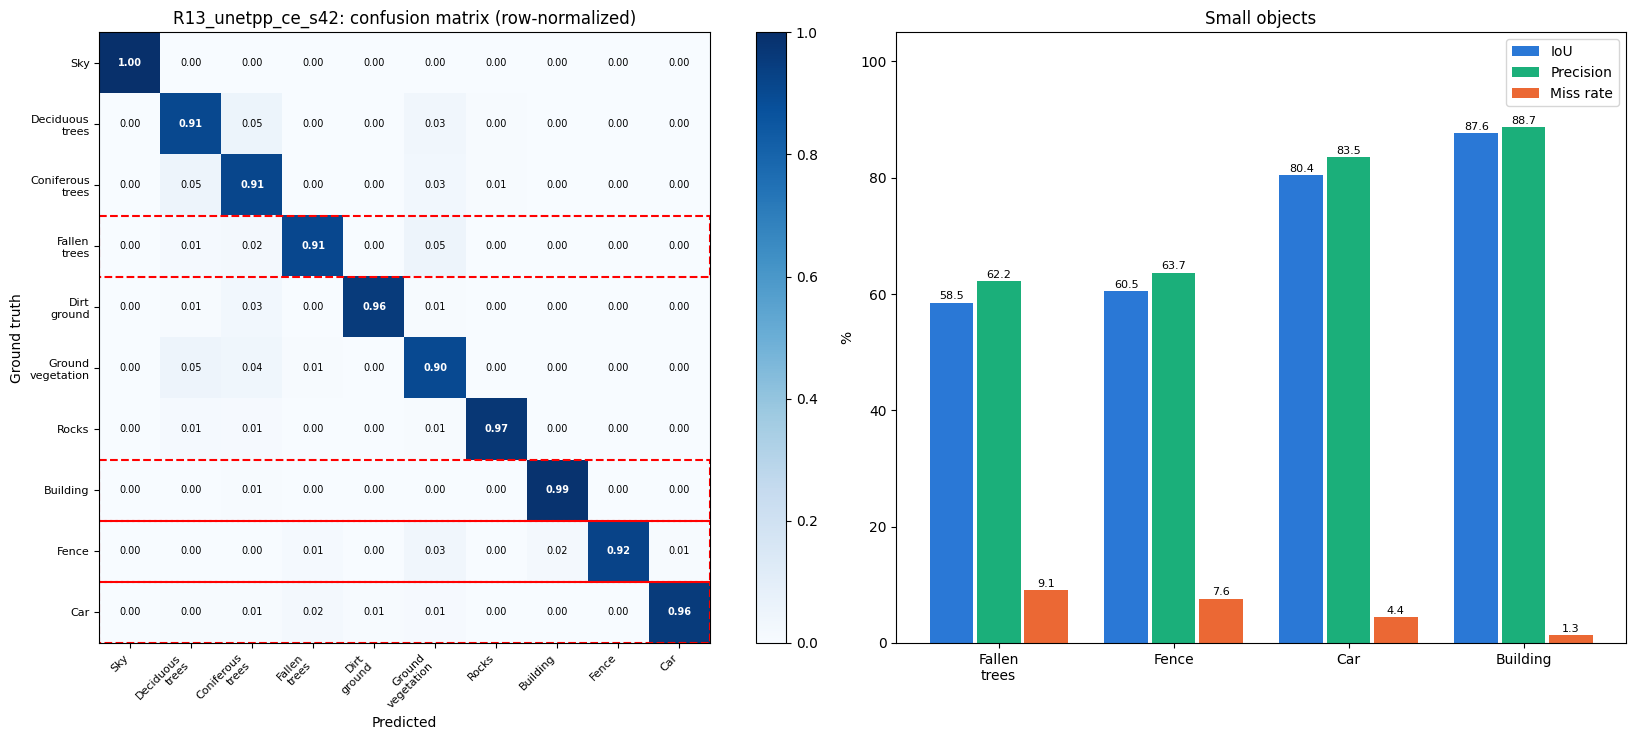

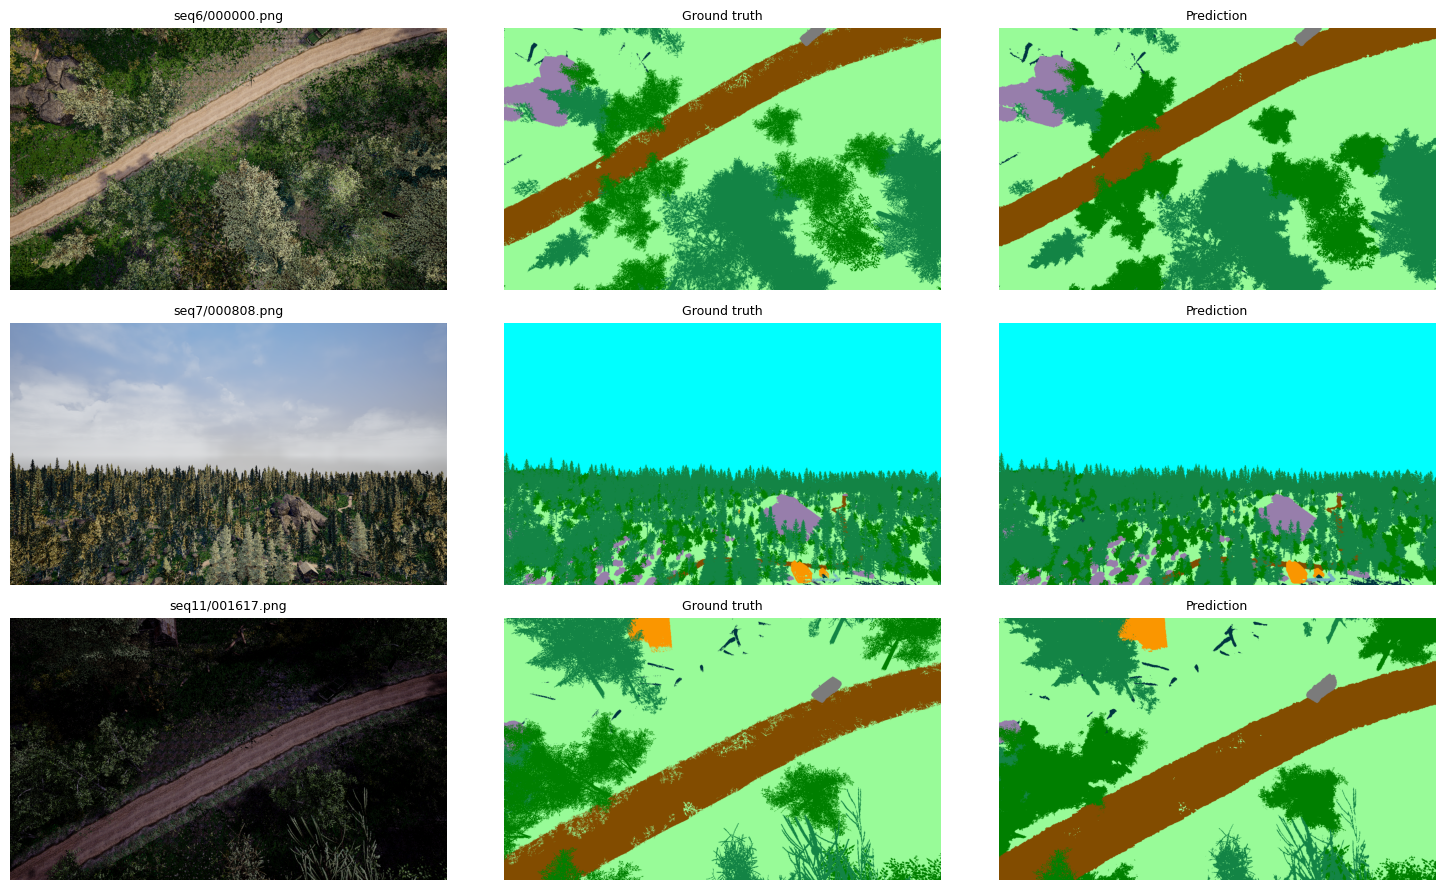

In [19]:
# ============================================================
# ANALYSIS FIGURES (same content as the old notebooks): small-object error analysis
# and sample predictions. Saved next to the results JSON.
# ============================================================
import matplotlib
import matplotlib.pyplot as plt

SMALL_CLASSES = {3: 'Fallen_trees', 8: 'Fence', 9: 'Car', 7: 'Building'}

if TRAINING_FINISHED:
    n = NUM_CLASSES - 1
    cm10 = cm_test[:n, :n].astype(float)
    cm_norm = np.divide(cm10, cm10.sum(1, keepdims=True), out=np.zeros_like(cm10), where=cm10.sum(1, keepdims=True) > 0)

    print('Small-object errors (test set):')
    for cid, name in SMALL_CLASSES.items():
        row = cm_test[cid].astype(float); row[cid] = 0; row[-1] = 0
        top = np.argsort(row)[::-1][:3]
        conf = ', '.join(f'{CLASS_NAMES[j]} {100 * row[j] / cm_test[cid].sum():.1f}%' for j in top if row[j] > 0)
        print(f'  {name:<14} IoU {100 * iou_t[cid]:5.2f} | recall {100 * rec_t[cid]:5.2f} | '
              f'precision {100 * prec_t[cid]:5.2f} | confused with: {conf}')

    fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={'width_ratios': [1.25, 1]})
    im = axes[0].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    labels = [c.replace('_', '\n') for c in CLASS_NAMES[:n]]
    axes[0].set_xticks(range(n)); axes[0].set_xticklabels(labels, fontsize=8, rotation=45, ha='right')
    axes[0].set_yticks(range(n)); axes[0].set_yticklabels(labels, fontsize=8)
    axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Ground truth')
    axes[0].set_title(f'{RUN_NAME}: confusion matrix (row-normalized)')
    plt.colorbar(im, ax=axes[0], fraction=0.046)
    for i in range(n):
        for j in range(n):
            axes[0].text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                         color='white' if cm_norm[i, j] > 0.5 else 'black', fontweight='bold' if i == j else 'normal')
    for cid in SMALL_CLASSES:
        axes[0].add_patch(plt.Rectangle((-0.5, cid - 0.5), n, 1, fill=False, edgecolor='red', lw=1.5, ls='--'))

    ids = list(SMALL_CLASSES)
    x = np.arange(len(ids)); w = 0.27
    for k, (vals, lab, col) in enumerate([([100 * iou_t[c] for c in ids], 'IoU', '#2a78d6'),
                                          ([100 * prec_t[c] for c in ids], 'Precision', '#1baf7a'),
                                          ([100 * (1 - rec_t[c]) for c in ids], 'Miss rate', '#eb6834')]):
        b = axes[1].bar(x + (k - 1) * w, vals, w - 0.02, label=lab, color=col)
        axes[1].bar_label(b, fmt='%.1f', fontsize=8, padding=1)
    axes[1].set_xticks(x); axes[1].set_xticklabels([SMALL_CLASSES[c].replace('_', '\n') for c in ids])
    axes[1].set_ylim(0, 105); axes[1].set_ylabel('%'); axes[1].legend(); axes[1].set_title('Small objects')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'small_object_error_analysis_{RUN_NAME}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # sample predictions: the same 3 test frames in every run, so runs can be compared side by side
    idx = np.linspace(0, len(test_files) - 1, 3).astype(int)
    fig, axes = plt.subplots(3, 3, figsize=(15, 9))
    with torch.no_grad():
        for r, i in enumerate(idx):
            img = np.array(Image.open(test_files[i][0]).convert('RGB'))
            gt = fast_rgb_to_mask(np.array(Image.open(test_files[i][1]).convert('RGB')))
            x_in = val_tf(image=img)['image'].unsqueeze(0).to(DEVICE)
            with torch.amp.autocast('cuda', enabled=USE_AMP):
                pred = model(x_in).argmax(1)[0].cpu().numpy()
            for c, (p, t) in enumerate([(img, Path(test_files[i][0]).parent.parent.name + '/' + Path(test_files[i][0]).name),
                                        (PALETTE[gt], 'Ground truth'), (PALETTE[pred], 'Prediction')]):
                axes[r, c].imshow(p); axes[r, c].set_title(t, fontsize=9); axes[r, c].axis('off')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'sample_predictions_{RUN_NAME}.png', dpi=120, bbox_inches='tight')
    plt.show()
